# Preparing the dataset for hippocampus segmentation

Completed Section 1 EDA notebook.

In [1]:
# TASK: Import the following libraries that we will use: nibabel, matplotlib, numpy
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import shutil

In [2]:
# TASK: Your data sits in directory /data/TrainingSet.
# Load an image and a segmentation mask into variables called image and label
data_dir = Path("/data/TrainingSet")
image_dir = data_dir / "images"
label_dir = data_dir / "labels"

image_files = sorted(image_dir.glob("*.nii.gz"))
label_files = sorted(label_dir.glob("*.nii.gz"))
print(f"Images: {len(image_files)}, Labels: {len(label_files)}")

image = nib.load(image_files[0])
label = nib.load(label_dir / image_files[0].name)
print("Loaded:", image_files[0].name)

Images: 263, Labels: 262
Loaded: hippocampus_001.nii.gz


Image shape: (35, 51, 35)
Label shape: (35, 51, 35)


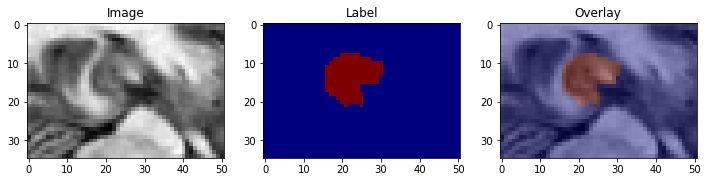

In [3]:
# TASK: using matplotlib, visualize a few slices from the dataset, along with their labels.
plt.rcParams["figure.figsize"] = (12, 4)

img_data = image.get_fdata()
lab_data = label.get_fdata()
print("Image shape:", img_data.shape)
print("Label shape:", lab_data.shape)

z = img_data.shape[2] // 2
fig, axes = plt.subplots(1, 3)
axes[0].imshow(img_data[:, :, z], cmap="gray")
axes[0].set_title("Image")
axes[1].imshow(lab_data[:, :, z], cmap="jet")
axes[1].set_title("Label")
axes[2].imshow(img_data[:, :, z], cmap="gray")
axes[2].imshow(lab_data[:, :, z], cmap="jet", alpha=0.4)
axes[2].set_title("Overlay")
plt.show()

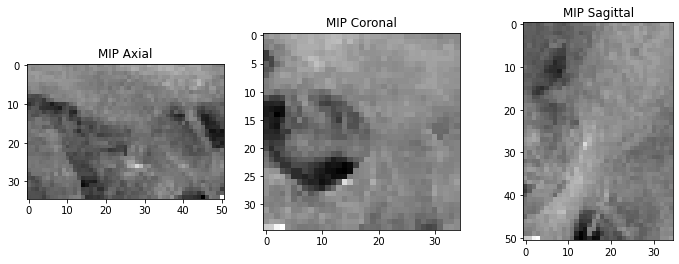

In [4]:
# Stand-out: simple volume rendering (MIP)
mip_axial = np.max(img_data, axis=2)
mip_coronal = np.max(img_data, axis=1)
mip_sagittal = np.max(img_data, axis=0)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(mip_axial, cmap="gray")
axes[0].set_title("MIP Axial")
axes[1].imshow(mip_coronal, cmap="gray")
axes[1].set_title("MIP Coronal")
axes[2].imshow(mip_sagittal, cmap="gray")
axes[2].set_title("MIP Sagittal")
plt.show()

In [5]:
# TASK: using .header_class attribute - what is the format of our images?
print("Format:", image.header_class)

Format: <class 'nibabel.nifti1.Nifti1Header'>


In [6]:
# TASK: How many bits per pixel are used?
print("bitpix:", image.header["bitpix"])
print("dtype:", image.get_data_dtype())

bitpix: 8
dtype: uint8


In [7]:
# TASK: What are the units of measurement?
print("Units:", image.header.get_xyzt_units())

Units: ('mm', 'sec')


In [8]:
# TASK: Do we have a regular grid? What are grid spacings?
print("Zooms (mm):", image.header.get_zooms()[:3])

Zooms (mm): (1.0, 1.0, 1.0)


In [9]:
# TASK: What dimensions represent axial, sagittal, and coronal slices?
print("Shape (sagittal, coronal, axial):", image.shape)
print("Axial = axis 2, Coronal = axis 1, Sagittal = axis 0")

Shape (sagittal, coronal, axial): (35, 51, 35)
Axial = axis 2, Coronal = axis 1, Sagittal = axis 0


In [10]:
# TASK: Compute the volume (in mm³) of a hippocampus
voxel_vol = np.prod(label.header.get_zooms()[:3])
hippo_voxels = np.sum(label.get_fdata() > 0)
print(f"Volume: {hippo_voxels * voxel_vol:.1f} mm³")

Volume: 2948.0 mm³


Valid: 262, min=2382, max=55824, mean=3496


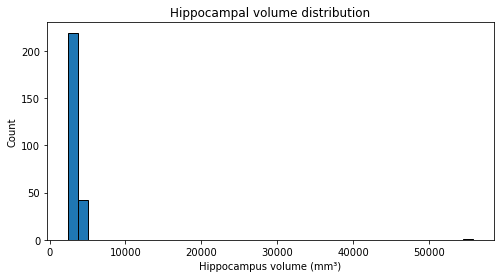

In [11]:
# TASK: Plot a histogram of all volumes
def get_volume(label_path):
    try:
        lab = nib.load(str(label_path))
        return np.sum(lab.get_fdata() > 0) * np.prod(lab.header.get_zooms()[:3])
    except Exception as e:
        print(f"Skipping {label_path.name}: {e}")
        return None

volumes = []
valid_pairs = []
for img_f in image_files:
    lab_f = label_dir / img_f.name
    if lab_f.exists():
        vol = get_volume(lab_f)
        if vol is not None:
            volumes.append(vol)
            valid_pairs.append((img_f, lab_f, vol))

volumes = np.array(volumes)
print(f"Valid: {len(volumes)}, min={volumes.min():.0f}, max={volumes.max():.0f}, mean={volumes.mean():.0f}")

plt.figure(figsize=(8, 4))
plt.hist(volumes, bins=40, edgecolor="black")
plt.xlabel("Hippocampus volume (mm³)")
plt.ylabel("Count")
plt.title("Hippocampal volume distribution")
plt.show()

In [12]:
# TASK: Copy the clean dataset to the output folder inside section1/out
q1, q3 = np.percentile(volumes, [25, 75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Keeping volumes between {lower:.0f} and {upper:.0f} mm³")

out_dir = Path("/home/workspace/section1/out")
(out_dir / "images").mkdir(parents=True, exist_ok=True)
(out_dir / "labels").mkdir(parents=True, exist_ok=True)

clean = 0
for img_f, lab_f, vol in valid_pairs:
    if lower <= vol <= upper:
        shutil.copy(img_f, out_dir / "images" / img_f.name)
        shutil.copy(lab_f, out_dir / "labels" / lab_f.name)
        clean += 1
    else:
        print(f"Removed: {img_f.name} ({vol:.0f} mm³)")

print(f"\nClean dataset: {clean} pairs saved to section1/out/")

Keeping volumes between 1939 and 4640 mm³
Removed: hippocampus_281.nii.gz (55824 mm³)

Clean dataset: 261 pairs saved to section1/out/


## Final remarks

Section 1 complete. Clean dataset is in `section1/out/`.